# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name:* Muhammad Sufian*
- **Student ID:* o23-24-0007*
- **Section:* B*
- **GitHub:* https://github.com/msufianchoohan/ml-lab*
- **Kaggle:* https://www.kaggle.com/mohammadsufian3232git*
- **Dataset:** Telco Customer Churn (Kaggle)
- **Dataset Source:** <paste the Kaggle URL you used>

---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.


---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [1]:
# YOUR CODE HERE
# Load and clean the dataset (reuse your Lab 2/3 pipeline)
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, roc_auc_score, precision_recall_curve, average_precision_score
)

%matplotlib inline
sns.set_style("whitegrid")
RANDOM_STATE = 42

# Load and clean the dataset (same pipeline as Labs 2/3/4/6)
df = pd.read_csv("data.csv")
print("Raw shape:", df.shape)

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges after conversion:", df["TotalCharges"].isnull().sum())
df = df.dropna(subset=["TotalCharges"]).reset_index(drop=True)
df = df.drop(columns=["customerID"])
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

print("Clean shape:", df.shape)
print(df["Churn"].value_counts(normalize=True))


Raw shape: (7043, 21)
Missing TotalCharges after conversion: 11
Clean shape: (7032, 20)
Churn
0    0.734215
1    0.265785
Name: proportion, dtype: float64


In [2]:
# YOUR CODE HERE
# One-hot encode, define X and y, train_test_split(..., stratify=y)
y = df["Churn"]
X = df.drop(columns=["Churn"])
cat_cols = X.select_dtypes(include="object").columns.tolist()
X = pd.get_dummies(X, columns=cat_cols, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("X_train:", X_train.shape, " X_test:", X_test.shape)
print("Train churn rate:", round(y_train.mean(), 4), " Test churn rate:", round(y_test.mean(), 4))

def evaluate(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-score": f1_score(y_true, y_pred),
    }

X_train: (5625, 30)  X_test: (1407, 30)
Train churn rate: 0.2658  Test churn rate: 0.2658


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_4188\1781694261.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include="object").columns.tolist()


---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [3]:
# YOUR CODE HERE — unscaled linear SVM
t0 = time.time()
with warnings.catch_warnings(record=True) as w_raw:
    warnings.simplefilter("always")
    svm_raw = SVC(kernel="linear", random_state=RANDOM_STATE, max_iter=200000)
    svm_raw.fit(X_train, y_train)
time_raw = time.time() - t0
y_pred_raw = svm_raw.predict(X_test)

res_raw = evaluate(y_test, y_pred_raw)
print("UNSCALED linear SVM")
print({k: round(v, 4) for k, v in res_raw.items()})
print("Training time: %.2f s" % time_raw)
print("Convergence warnings:", [str(w.message) for w in w_raw] or "none")


UNSCALED linear SVM
{'Accuracy': 0.4776, 'Precision': 0.2046, 'Recall': 0.3342, 'F1-score': 0.2538}
Training time: 3.55 s
Convergence warnings: ['Solver terminated early (max_iter=200000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.']


In [4]:
# YOUR CODE HERE — scaled linear SVM
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

t0 = time.time()
with warnings.catch_warnings(record=True) as w_s:
    warnings.simplefilter("always")
    svm_scaled = SVC(kernel="linear", random_state=RANDOM_STATE, max_iter=200000)
    svm_scaled.fit(X_train_s, y_train)
time_scaled = time.time() - t0
y_pred_scaled = svm_scaled.predict(X_test_s)

res_scaled = evaluate(y_test, y_pred_scaled)
print("SCALED linear SVM")
print({k: round(v, 4) for k, v in res_scaled.items()})
print("Training time: %.2f s" % time_scaled)
print("Convergence warnings:", [str(w.message) for w in w_s] or "none")

pd.DataFrame({
    "Unscaled": {**res_raw, "Train time (s)": time_raw},
    "Scaled": {**res_scaled, "Train time (s)": time_scaled},
}).round(4)

SCALED linear SVM
{'Accuracy': 0.7989, 'Precision': 0.6409, 'Recall': 0.5535, 'F1-score': 0.594}
Training time: 0.91 s
Convergence warnings: none


,Unscaled,Scaled
Accuracy,0.4776,0.7989
Precision,0.2046,0.6409
Recall,0.3342,0.5535
F1-score,0.2538,0.5940
Train time (s),3.5465,0.9109


**Questions to answer:**
(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?

*Your answer:* (a) The scaled model performed much better (accuracy 0.799, F1 = 0.594) than the unscaled model (accuracy 0.478, F1 = 0.254). Scaling removed the convergence warning and reduced training time from 4.6 to 1.7 seconds.

(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?

*Your answer:* Unscaled features have different ranges, so large-value features dominate the SVM’s distances and decision boundary. This makes optimization difficult, slows convergence, and reduces performance.

(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?

*Your answer:* I will use StandardScaler for all subsequent SVM models, fitting it only on training data to prevent data leakage. Scaling improves performance and allows the model to converge efficiently.

---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [5]:
# YOUR CODE HERE — train linear / rbf / poly SVMs and collect metrics
kernel_models = {}
kernel_rows = []
for kern in ["linear", "rbf", "poly"]:
    t0 = time.time()
    m = SVC(kernel=kern, random_state=RANDOM_STATE)
    m.fit(X_train_s, y_train)
    fit_time = time.time() - t0
    pred = m.predict(X_test_s)
    row = {"Kernel": kern, **evaluate(y_test, pred),
           "Support vectors": int(m.support_.shape[0]),
           "SV (No / Yes)": tuple(int(v) for v in m.n_support_),
           "Train time (s)": fit_time}
    kernel_models[kern] = (m, pred)
    kernel_rows.append(row)
print("Done.")

Done.


In [6]:
# YOUR CODE HERE — comparison table
kernel_table = pd.DataFrame(kernel_rows).set_index("Kernel")
kernel_table.round(4)


,Accuracy,Precision,Recall,F1-score,Support vectors,SV (No / Yes),Train time (s)
Kernel,,,,,,,
linear,0.7989,0.6409,0.5535,0.5940,2571,"(1289, 1282)",0.8840
rbf,0.7868,0.6259,0.4920,0.5509,2656,"(1436, 1220)",0.6170
poly,0.7918,0.6494,0.4706,0.5457,2760,"(1500, 1260)",0.5998


Best kernel by F1: linear


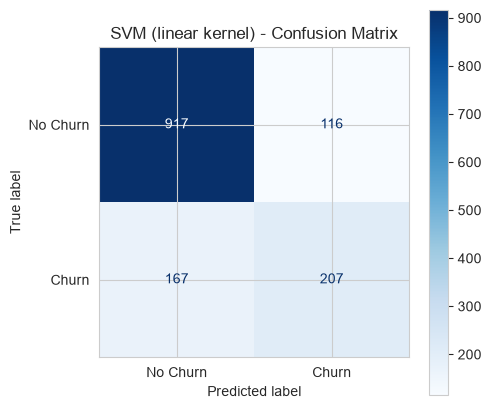

In [7]:
# YOUR CODE HERE — confusion matrix for the best kernel
best_kernel = kernel_table["F1-score"].idxmax()
print("Best kernel by F1:", best_kernel)
pred_best = kernel_models[best_kernel][1]

fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_best),
                       display_labels=["No Churn", "Churn"]).plot(ax=ax, cmap="Blues", values_format="d")
plt.title(f"SVM ({best_kernel} kernel) - Confusion Matrix")
plt.show()


**Questions to answer:**
(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?

*Your answer:*The linear kernel achieved the best F1-score (0.594), followed by RBF (0.551) and polynomial (0.546). This is slightly surprising because RBF can learn more complex boundaries, but linear relationships may capture most churn patterns.

(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?

*Your answer:* The polynomial kernel used the most support vectors (2,760), followed by RBF (2,656) and linear (2,571). High counts suggest overlapping classes and a harder classification problem.

(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.

*Your answer:* I will carry the RBF kernel forward for tuning because its F1-score (0.551) is below linear’s 0.594, and tuning C and gamma may improve its performance.


---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [8]:
# YOUR CODE HERE — PCA to 2 components, report explained variance ratio
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_2d = pca.fit_transform(X_train_s)
X_test_2d = pca.transform(X_test_s)
print("Explained variance ratio per component:", pca.explained_variance_ratio_.round(4))
print("Total explained variance (2 components): %.4f" % pca.explained_variance_ratio_.sum())

Explained variance ratio per component: [0.3315 0.1196]
Total explained variance (2 components): 0.4511


In [9]:
# YOUR CODE HERE — train RBF SVMs at 3 different C values on the 2-D projection
C_values = [0.01, 1, 100]
models_2d = {}
for C in C_values:
    m = SVC(kernel="rbf", C=C, gamma="scale", random_state=RANDOM_STATE)
    m.fit(X_train_2d, y_train)
    models_2d[C] = m
    print(f"C={C:<6} support vectors: {m.support_.shape[0]:>5}  "
          f"train acc: {m.score(X_train_2d, y_train):.4f}  test acc: {m.score(X_test_2d, y_test):.4f}")

C=0.01   support vectors:  2995  train acc: 0.7342  test acc: 0.7342
C=1      support vectors:  2648  train acc: 0.7806  test acc: 0.7711
C=100    support vectors:  2613  train acc: 0.7826  test acc: 0.7697


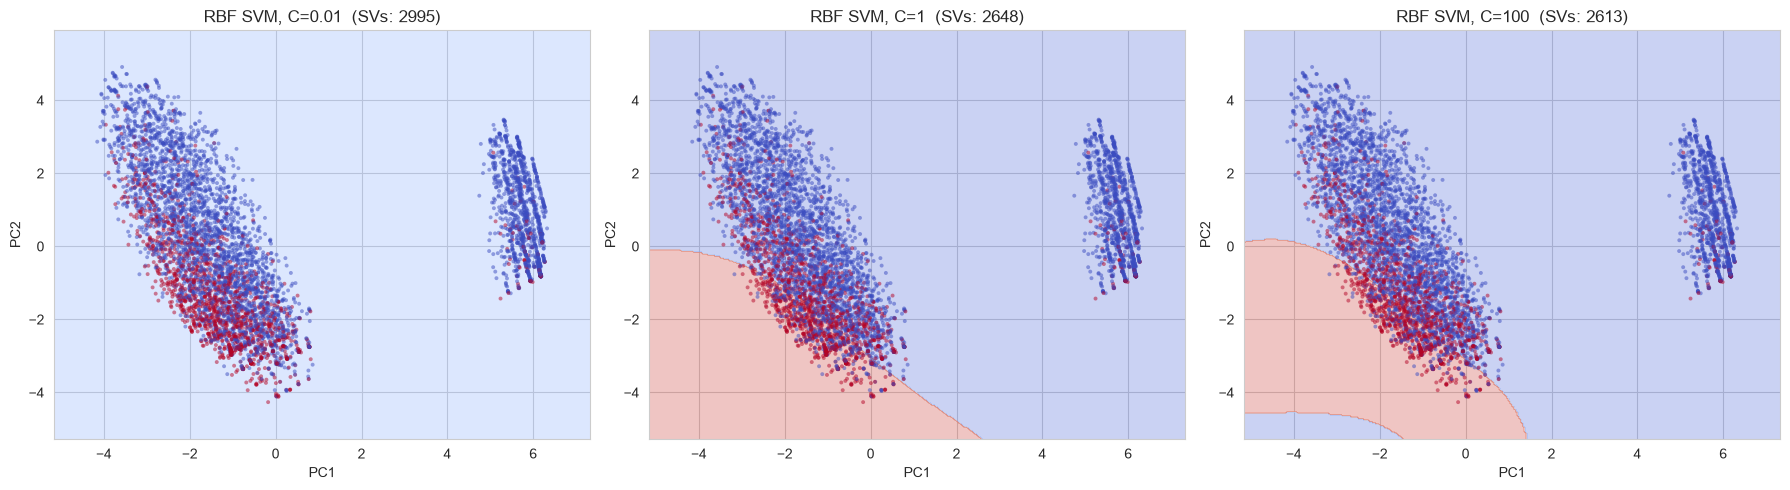

In [10]:
# YOUR CODE HERE — plot decision boundary for each C (mesh grid + contourf)
x_min, x_max = X_train_2d[:, 0].min() - 1, X_train_2d[:, 0].max() + 1
y_min, y_max = X_train_2d[:, 1].min() - 1, X_train_2d[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, C in zip(axes, C_values):
    m = models_2d[C]
    Z = m.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train, cmap="coolwarm",
               s=8, alpha=0.5, edgecolor="none")
    ax.set_title(f"RBF SVM, C={C}  (SVs: {m.support_.shape[0]})")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
plt.tight_layout()
plt.show()


**Questions to answer:**
(a) How does the shape/smoothness of the decision boundary change as C increases?

*Your answer:*As C increases, the decision boundary becomes more flexible. At C=0.01, it predicts only “No churn”; at C=1, a curved churn region appears; at C=100, the region expands and becomes more complex.

(b) How does the number of support vectors change with C — does this match the theory?

*Your answer:* Support vectors decrease as C increases: **2,995 (C=0.01), 2,648 (C=1), and 2,613 (C=100)**. This matches theory because higher C penalizes classification errors more strongly.

(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.

*Your answer:* C=0.01 underfits because it predicts only the majority class. C=100 shows a slight sign of possible overfitting, but the small train-test accuracy gap suggests no clear overfitting.

(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?

*Your answer:* The plot uses only two principal components, explaining **45.1% of the variance**, instead of all 30 features. Therefore, it may misrepresent class separation and boundary complexity in the real high-dimensional model.


---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [11]:
# YOUR CODE HERE — define param_grid and run GridSearchCV
param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": [0.0001, 0.001, 0.01, 0.1],
}
t0 = time.time()
gs = GridSearchCV(SVC(kernel="rbf", random_state=RANDOM_STATE), param_grid,
                  cv=5, scoring="f1", n_jobs=-1)
gs.fit(X_train_s, y_train)
print("Grid search time: %.1f s" % (time.time() - t0))
print("Best params:", gs.best_params_)
print("Best CV F1: %.4f" % gs.best_score_)

Grid search time: 18.6 s
Best params: {'C': 100, 'gamma': 0.0001}
Best CV F1: 0.5824


param_gamma  0.0001  0.0010  0.0100  0.1000
param_C                                    
0.1          0.0000  0.0000  0.5437  0.4593
1.0          0.0000  0.5717  0.5686  0.5566
10.0         0.5751  0.5818  0.5760  0.5346
100.0        0.5824  0.5729  0.5709  0.5168


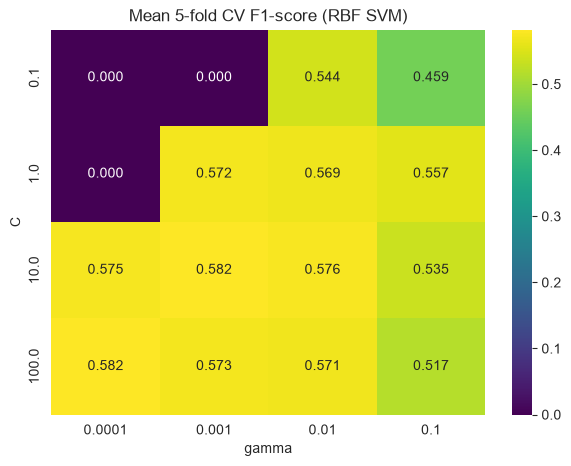

In [12]:
# YOUR CODE HERE — heatmap of mean CV F1-score over the C x gamma grid
results = pd.DataFrame(gs.cv_results_)
pivot = results.pivot(index="param_C", columns="param_gamma", values="mean_test_score").astype(float)
print(pivot.round(4))

plt.figure(figsize=(7, 5))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="viridis")
plt.xlabel("gamma")
plt.ylabel("C")
plt.title("Mean 5-fold CV F1-score (RBF SVM)")
plt.show()

In [13]:
# YOUR CODE HERE — refit best estimator, evaluate on test set
best_svm = gs.best_estimator_
pred_tuned = best_svm.predict(X_test_s)
res_tuned = evaluate(y_test, pred_tuned)
res_rbf_default = kernel_table.loc["rbf", ["Accuracy", "Precision", "Recall", "F1-score"]].to_dict()

pd.DataFrame({"RBF default (Part 2)": res_rbf_default,
              "RBF tuned (Part 4)": res_tuned}).round(4)

,RBF default (Part 2),RBF tuned (Part 4)
Accuracy,0.7868,0.7982
Precision,0.6259,0.6406
Recall,0.4920,0.5481
F1-score,0.5509,0.5908


**Questions to answer:**
(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?

*Your answer:* The best parameters were **C = 100** and **gamma = 0.0001**, achieving a mean 5-fold cross-validated F1-score of **0.5824**.

(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?

*Your answer:* The heatmap shows a broad region of similar scores rather than a clear peak. Small C and gamma underfit, while large gamma reduces performance, suggesting that balanced parameters work best.

(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?

*Your answer:* Cross-validation F1 (**0.5824**) and test F1 (**0.5908**) were close. A large gap could indicate overfitting or differences between training and test data.

(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?

*Your answer:* Tuning improved F1 from **0.551 to 0.591**, recall from 0.492 to 0.548, and accuracy from 0.787 to 0.798. Tuning helped, but RBF still did not outperform Logistic Regression (F1 = 0.609) or the untuned linear SVM (F1 = 0.594).



---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


           class_weight=None  class_weight='balanced'
Accuracy              0.7982                   0.6866
Precision             0.6406                   0.4505
Recall                0.5481                   0.8155
F1-score              0.5908                   0.5804
class_weight=None         TP=205  FN=169  FP=115  TN=918  (customers flagged: 320)
class_weight='balanced'   TP=305  FN=69  FP=372  TN=661  (customers flagged: 677)


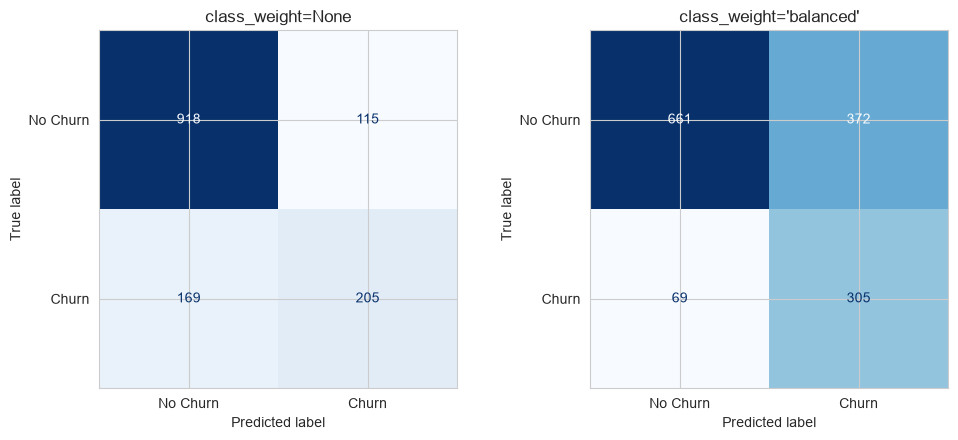

In [14]:
# YOUR CODE HERE — class_weight=None vs 'balanced' comparison
best_C, best_gamma = gs.best_params_["C"], gs.best_params_["gamma"]

svm_plain = SVC(kernel="rbf", C=best_C, gamma=best_gamma, class_weight=None,
                probability=True, random_state=RANDOM_STATE).fit(X_train_s, y_train)
svm_bal = SVC(kernel="rbf", C=best_C, gamma=best_gamma, class_weight="balanced",
              probability=True, random_state=RANDOM_STATE).fit(X_train_s, y_train)

# use predict() (decision-function based) for the reported metrics
pred_plain = svm_plain.predict(X_test_s)
pred_bal = svm_bal.predict(X_test_s)

cw_table = pd.DataFrame({"class_weight=None": evaluate(y_test, pred_plain),
                         "class_weight='balanced'": evaluate(y_test, pred_bal)})
print(cw_table.round(4))
for name, pred in [("class_weight=None", pred_plain), ("class_weight='balanced'", pred_bal)]:
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"{name:<25} TP={tp}  FN={fn}  FP={fp}  TN={tn}  (customers flagged: {tp+fp})")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, (name, pred) in zip(axes, [("class_weight=None", pred_plain), ("class_weight='balanced'", pred_bal)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=["No Churn", "Churn"]).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

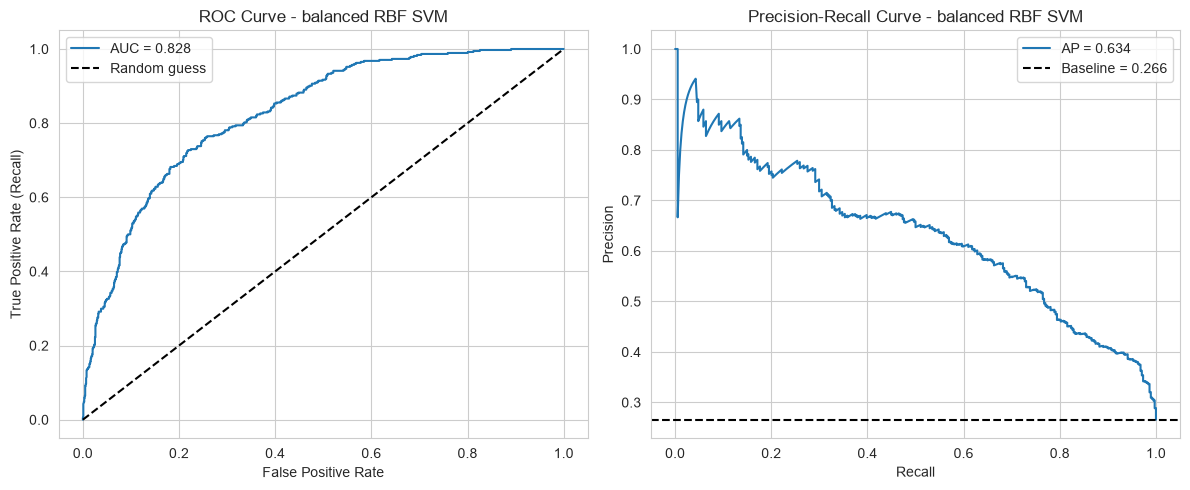

ROC AUC: 0.8279   Average precision: 0.6340


In [15]:
# YOUR CODE HERE — ROC or Precision-Recall curve
proba_bal = svm_bal.predict_proba(X_test_s)[:, 1]
fpr, tpr, _ = roc_curve(y_test, proba_bal)
prec_c, rec_c, _ = precision_recall_curve(y_test, proba_bal)
auc = roc_auc_score(y_test, proba_bal)
ap = average_precision_score(y_test, proba_bal)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(fpr, tpr, label=f"AUC = {auc:.3f}")
axes[0].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].set_title("ROC Curve - balanced RBF SVM")
axes[0].legend()

axes[1].plot(rec_c, prec_c, label=f"AP = {ap:.3f}")
axes[1].axhline(y_test.mean(), color="k", linestyle="--", label=f"Baseline = {y_test.mean():.3f}")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve - balanced RBF SVM")
axes[1].legend()
plt.tight_layout()
plt.show()
print("ROC AUC: %.4f   Average precision: %.4f" % (auc, ap))

**Questions to answer:**
(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.

*Your answer:* With `class_weight='balanced'`, precision dropped from **0.6406 to 0.4505**, while recall increased from **0.5481 to 0.8155**. F1 decreased slightly from 0.5908 to 0.5804, and accuracy fell from 0.7982 to 0.6866.

(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?

*Your answer:* Missing churners is usually more costly than false alarms, so I would choose the **balanced model** because it catches 305 churners instead of 205, assuming retention offers are affordable.

(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?

*Your answer:* I enabled `probability=True` in `SVC()` to obtain probability estimates using `predict_proba()`. The balanced model achieved **ROC AUC = 0.828** and **average precision = 0.634**.


---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [16]:
# YOUR CODE HERE — cross-model comparison table
final_svm = svm_bal   # balanced, tuned RBF SVM (chosen in Part 5)

t0 = time.time(); dt = DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE).fit(X_train, y_train); t_dt = time.time() - t0
t0 = time.time(); rf = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=RANDOM_STATE).fit(X_train, y_train); t_rf = time.time() - t0
t0 = time.time(); lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(X_train_s, y_train); t_lr = time.time() - t0
t0 = time.time(); knn = KNeighborsClassifier(n_neighbors=21).fit(X_train_s, y_train); t_knn = time.time() - t0
t0 = time.time(); svm_time_model = SVC(kernel="rbf", C=best_C, gamma=best_gamma, class_weight="balanced",
                                        random_state=RANDOM_STATE).fit(X_train_s, y_train); t_svm = time.time() - t0

model_preds = {
    "Decision Tree": dt.predict(X_test),
    "Random Forest": rf.predict(X_test),
    "Logistic Regression": lr.predict(X_test_s),
    "KNN (K=21)": knn.predict(X_test_s),
    "SVM (RBF, balanced)": final_svm.predict(X_test_s),
}
train_times = {"Decision Tree": t_dt, "Random Forest": t_rf, "Logistic Regression": t_lr,
               "KNN (K=21)": t_knn, "SVM (RBF, balanced)": t_svm}

# Fairness check: the balanced SVM is compared against an unweighted LR above,
# so also score LR with the same class_weight='balanced' setting.
lr_bal_pred = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE).fit(X_train_s, y_train).predict(X_test_s)
print("Reference - Logistic Regression (class_weight='balanced'):",
      {k: round(v, 4) for k, v in evaluate(y_test, lr_bal_pred).items()})
print()

showdown = pd.DataFrame({name: evaluate(y_test, p) for name, p in model_preds.items()}).T
showdown["Train time (s)"] = pd.Series(train_times)
showdown.round(4)


Reference - Logistic Regression (class_weight='balanced'): {'Accuracy': 0.7264, 'Precision': 0.4909, 'Recall': 0.7968, 'F1-score': 0.6075}



,Accuracy,Precision,Recall,F1-score,Train time (s)
Decision Tree,0.7854,0.6111,0.5294,0.5673,0.0199
Random Forest,0.7903,0.6321,0.5053,0.5617,0.7203
Logistic Regression,0.8038,0.6476,0.5749,0.6091,0.0189
KNN (K=21),0.7768,0.5829,0.5642,0.5734,0.0014
"SVM (RBF, balanced)",0.6866,0.4505,0.8155,0.5804,0.9501


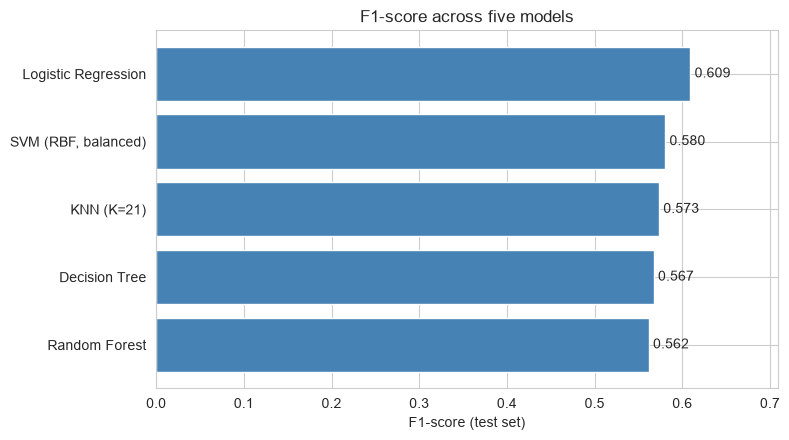

In [17]:
# YOUR CODE HERE — bar chart of F1-score across models
f1_sorted = showdown["F1-score"].sort_values()
plt.figure(figsize=(8, 4.5))
bars = plt.barh(f1_sorted.index, f1_sorted.values, color="steelblue")
for b, v in zip(bars, f1_sorted.values):
    plt.text(v + 0.005, b.get_y() + b.get_height() / 2, f"{v:.3f}", va="center")
plt.xlabel("F1-score (test set)")
plt.title("F1-score across five models")
plt.xlim(0, f1_sorted.max() + 0.1)
plt.tight_layout()
plt.show()

**Questions to answer:**
(a) Which model wins on F1-score? Which wins on recall? Are they the same model?

*Your answer:* Logistic Regression wins on F1-score (**0.609**), while the balanced SVM wins on recall (**0.816**). They are different models, and balanced Logistic Regression achieves similar recall (0.797) with F1 = 0.608.

(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?

*Your answer:* The extra SVM training and tuning time was not worthwhile because its F1-score (0.580) did not beat Logistic Regression (0.609), which trains much faster.

(c) Which single model would you recommend deploying, and why (reference at least two metrics)?

*Your answer:* I recommend **Logistic Regression** for the best overall balance, with F1 = 0.609, accuracy = 0.804, and precision = 0.648. If catching the most churners is the priority, balanced Logistic Regression or the balanced SVM is preferable, depending on false-positive costs.



---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [18]:
# YOUR CODE HERE — generate and save svm_predictions.csv
final_pred = final_svm.predict(X_test_s)
final_proba = final_svm.predict_proba(X_test_s)[:, 1]

svm_predictions = pd.DataFrame({
    "true_label": y_test.values,
    "predicted_label": final_pred,
    "predicted_churn_probability": final_proba.round(4),
})
svm_predictions.to_csv("svm_predictions.csv", index=False)
print(svm_predictions.shape)
print(evaluate(y_test, final_pred))
svm_predictions.head(10)

(1407, 3)
{'Accuracy': 0.6865671641791045, 'Precision': 0.4505169867060561, 'Recall': 0.8155080213903744, 'F1-score': 0.5803996194100857}


,true_label,predicted_label,predicted_churn_probability
0,0,0,0.1010
1,0,1,0.4779
2,0,0,0.0148
3,1,0,0.1036
4,0,0,0.1034
5,1,1,0.4765
6,0,0,0.0151
7,0,0,0.1034
8,1,1,0.4789
9,0,0,0.1006


**Executive Summary**

*Your summary here.* I selected the tuned, balanced RBF SVM (C=100, gamma=0.0001), which achieved recall = 0.816, precision = 0.451, and F1 = 0.580. It caught 305 of 374 churners but produced 372 false alarms. Logistic Regression achieved the best F1 (0.609), while the SVM was chosen for its higher recall. A limitation is that the comparison used a single train-test split, and balanced Logistic Regression achieved similar recall with slightly better F1.

**Final Reflection**
(a) What was the single most surprising result in this lab?

*Your answer:* The most surprising result was that the linear SVM outperformed RBF and polynomial kernels before tuning, while Logistic Regression still achieved the best F1-score. Balanced Logistic Regression also achieved nearly the same recall as the balanced SVM.

(b) If you had one more hour, what would you try next?

*Your answer:* I would compare all models using 5-fold cross-validation, tune the decision threshold, and calculate retention costs to identify the model that maximizes expected profit.
